# 02a — Rezagos e índice

Bloques 1–2 del cuaderno 02: rezagos (solo memoria) e índice meteorológico. Escribe `expanded/firms_spain_final_lags_index.csv`.

# 1 — Variables de rezago para `wildfire_data_cleaned.csv`

Este notebook crea variables meteorológicas retrospectivas para cada observación. Agrega las mediciones disponibles por **comunidad autónoma y fecha** y calcula los rezagos sobre días naturales. Así, los periodos previos excluyen el día de la observación.

**Importante:** el CSV contiene observaciones de incendios, no una tabla meteorológica diaria completa e independiente. Los promedios diarios regionales se calculan a partir de las filas disponibles del propio CSV. Los valores deben interpretarse como aproximaciones regionales basadas en esas observaciones; no como clima exacto en cada coordenada. Las ventanas se dejan como `NaN` si falta cualquiera de sus días.

## Imports (celda única del cuaderno)

In [1]:
# Imports del cuaderno (celda única) — todas las dependencias aquí; las demás celdas no importan nada.
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from wildfire.data.io import load_csv, save_csv


### 1.1 — Carga y fechas

Carga el CSV limpio y normaliza `acq_date`; punto de partida del bloque.

In [2]:

df = load_csv("data/processed/expanded/wildfire_data_cleaned.csv")

df['acq_date'] = pd.to_datetime(df['acq_date'], errors='coerce').dt.normalize()
required = {'acq_date', 'ccaa', 'precipitation', 'temperature_2m'}
missing = required.difference(df.columns)
if missing:
    raise ValueError(f'Faltan columnas necesarias: {sorted(missing)}')

print(f'{len(df):,} filas; fechas {df.acq_date.min().date()} a {df.acq_date.max().date()}')
print(f"Comunidades autónomas: {df['ccaa'].nunique(dropna=True)}")
df.head()


23,142 filas; fechas 2023-01-01 a 2024-12-31
Comunidades autónomas: 17


,latitude,longitude,brightness,scan,acq_date,acq_time,brightness_ir,frp,daynight,type,...,day_of_year_sin,day_of_year_cos,sup_forestal_ha,ratio_prevencion_extincion,euros_prevencion_por_ha,euros_extincion_por_ha,potencial_propagacion,indice_riesgo_meteo,estres_termico_vegetacion,indice_riesgo_meteo_log
0,43.1262,-4.0911,316.0,1.1,2023-01-01,221,273.7,20.4,N,0,...,0.017202,0.999852,360000,0.492424,18.055556,36.666667,12.783511,32.892090,0.223829,3.523182
1,39.2047,-1.7606,304.4,1.0,2023-01-01,1326,286.6,6.2,D,0,...,0.017202,0.999852,3600000,0.857143,33.333333,38.888889,5.086914,23.380942,0.298169,3.193802
2,42.3885,-2.7282,301.2,3.1,2023-01-03,1008,279.5,40.0,D,0,...,0.051584,0.998669,340000,0.512195,18.529412,36.176471,0.960729,2.737120,0.075261,1.318315
3,38.5923,-1.0710,304.7,1.1,2023-01-03,1313,291.0,6.3,D,0,...,0.051584,0.998669,510000,0.467742,28.431373,60.784314,1.559968,33.912346,0.251509,3.552841
4,38.7134,-0.7309,302.0,1.0,2023-01-03,1313,288.8,5.0,D,0,...,0.051584,0.998669,1300000,0.595092,74.615385,125.384615,3.824963,24.518993,0.218192,3.239423


## Definición de las variables

Se calculan precipitación acumulada en los 3, 7 y 15 días anteriores; temperatura media en los 3, 7 y 15 días anteriores; y rezagos de un día para otras variables meteorológicas disponibles. Las ventanas usan días naturales y son estrictas: requieren datos diarios para todo el periodo.

### 1.2 — Medias diarias y rezagos

Agrega por CCAA×día y calcula `lag_1d`, sumas de precipitación y medias de temperatura a 3/7/15 días; produce `df_lags` (solo memoria).

In [3]:
# Variables meteorológicas disponibles en el archivo.
weather_cols = [c for c in [
    'precipitation', 'rain', 'temperature_2m', 'relative_humidity_2m',
    'wind_speed_10m', 'wind_gusts_10m', 'vapour_pressure_deficit',
    'surface_pressure', 'soil_moisture_0_to_7cm', 'soil_moisture_7_to_28cm',
    'shortwave_radiation', 'et0_fao_evapotranspiration', 'boundary_layer_height'
] if c in df.columns]

# Para evitar que el texto u otros valores no numéricos contaminen los promedios.
for col in weather_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Una media por comunidad y día a partir de las filas disponibles.
daily = (df.dropna(subset=['acq_date', 'ccaa'])
         .groupby(['ccaa', 'acq_date'], as_index=False)[weather_cols]
         .mean())

date_min, date_max = df['acq_date'].min(), df['acq_date'].max()
feature_frames = []
for region, part in daily.groupby('ccaa', sort=False):
    part = part.set_index('acq_date').sort_index()
    # Reindexado a días naturales: los días sin observación permanecen ausentes.
    calendar = pd.date_range(date_min, date_max, freq='D')
    part = part.reindex(calendar)
    part.index.name = 'acq_date'
    features = pd.DataFrame(index=part.index)
    features['ccaa'] = region

    # Valor del día inmediatamente anterior (día t-1).
    for col in weather_cols:
        features[f'{col}_lag_1d'] = part[col].shift(1)

    # Precipitación acumulada en los N días anteriores, sin incluir el día t.
    if 'precipitation' in part:
        for n in (3, 7, 15):
            features[f'precipitation_sum_prev_{n}d'] = part['precipitation'].shift(1).rolling(n, min_periods=n).sum()
    # Temperatura media en los N días anteriores, sin incluir el día t.
    if 'temperature_2m' in part:
        for n in (3, 7, 15):
            features[f'temperature_2m_mean_prev_{n}d'] = part['temperature_2m'].shift(1).rolling(n, min_periods=n).mean()
    feature_frames.append(features.reset_index())

lag_features = pd.concat(feature_frames, ignore_index=True)
lag_cols = [c for c in lag_features.columns if c not in ('ccaa', 'acq_date')]
df_lags = df.merge(lag_features, on=['ccaa', 'acq_date'], how='left', validate='many_to_one')
print(f'Variables nuevas: {len(lag_cols)}')
df_lags[['acq_date', 'ccaa', 'precipitation', 'temperature_2m'] + lag_cols[:8]].head(10)

Variables nuevas: 19


,acq_date,ccaa,precipitation,temperature_2m,precipitation_lag_1d,rain_lag_1d,temperature_2m_lag_1d,relative_humidity_2m_lag_1d,wind_speed_10m_lag_1d,wind_gusts_10m_lag_1d,vapour_pressure_deficit_lag_1d,surface_pressure_lag_1d
0,2023-01-01,Cantabria,0.0,12.653500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2023-01-01,Castilla-La Mancha,0.0,15.485000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2023-01-03,La Rioja,0.0,6.254333,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2023-01-03,Región de Murcia,0.0,15.236666,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2023-01-03,Comunidad Valenciana,0.1,14.955833,0.000,0.000,16.365833,57.820268,3.376023,12.401999,0.833029,1018.296622
5,2023-01-03,Región de Murcia,0.0,17.515001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,2023-01-03,Comunidad Valenciana,0.0,17.685000,0.000,0.000,16.365833,57.820268,3.376023,12.401999,0.833029,1018.296622
7,2023-01-03,Región de Murcia,0.0,16.570832,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,2023-01-04,Aragón,0.0,6.438333,0.000,0.000,9.050500,68.675090,4.389880,15.813000,0.362963,924.883549
9,2023-01-04,Comunidad Valenciana,0.0,14.750000,0.025,0.025,16.637917,60.515075,5.761760,16.792499,0.755394,1001.308906


## Revisar cobertura y guardar

Las fechas iniciales y los periodos con días regionales ausentes tendrán valores nulos. Revise la cobertura antes de usar estas variables en un modelo.

**Aviso:** los rezagos no se exportan a CSV a propósito — el reindexado a días naturales más la exigencia de ventanas completas dejan una cobertura de NaN muy alta. `df_lags` vive solo en memoria y se revisitará más adelante.

### 1.3 — Cobertura de NaNs

Informa la cobertura de cada rezago; inicios y huecos regionales quedan como NaN por diseño.

In [4]:
coverage = df_lags[lag_cols].notna().mean().sort_values(ascending=False).rename('proporcion_no_nula')
display(coverage.to_frame())

print(df_lags.isna().sum())

,proporcion_no_nula
precipitation_lag_1d,0.820543
rain_lag_1d,0.820543
temperature_2m_lag_1d,0.820543
relative_humidity_2m_lag_1d,0.820543
wind_speed_10m_lag_1d,0.820543
wind_gusts_10m_lag_1d,0.820543
vapour_pressure_deficit_lag_1d,0.820543
surface_pressure_lag_1d,0.820543
soil_moisture_0_to_7cm_lag_1d,0.820543
soil_moisture_7_to_28cm_lag_1d,0.820543


latitude                            0
longitude                           0
brightness                          0
scan                                0
acq_date                            0
                                ...  
precipitation_sum_prev_7d       17005
precipitation_sum_prev_15d      21615
temperature_2m_mean_prev_3d     10091
temperature_2m_mean_prev_7d     17005
temperature_2m_mean_prev_15d    21615
Length: 77, dtype: int64


# 2 — Índice meteorológico compuesto de peligro de incendio

Este notebook combina las variables meteorológicas presentes en `firms_spain_final.csv` en un **índice relativo de 0 a 100**. Se usan temperatura, humedad relativa, viento, precipitación, déficit de presión de vapor (VPD) y humedad del suelo.

## Interpretación y límites

Es un índice exploratorio construido para este archivo, **no es el Fire Weather Index (FWI) oficial ni una predicción validada**. Las variables se convierten en percentiles dentro de las filas del CSV; por ello, el resultado indica posición relativa frente a las observaciones de este conjunto, no un nivel absoluto de peligro. Además, el CSV contiene localizaciones con detecciones de incendios, así que no representa todas las condiciones meteorológicas de España. No debe usarse por sí solo para alertas ni decisiones operativas.

Las ponderaciones iniciales son explícitas y editables: temperatura 20%, humedad relativa 20%, viento 20%, precipitación 15%, VPD 15% y humedad del suelo 10%. Los valores altos de temperatura, viento y VPD elevan el score; valores altos de humedad relativa, precipitación y humedad del suelo lo reducen. Se requiere un mínimo de cuatro componentes disponibles por fila; el score ponderado se ajusta a los componentes presentes.

### 2.1 — Carga y requisitos

Carga el CSV limpio y exige las 6 variables del índice.

In [5]:

df = load_csv("data/processed/expanded/wildfire_data_cleaned.csv")
required = ['temperature_2m', 'relative_humidity_2m', 'wind_speed_10m', 'precipitation', 'vapour_pressure_deficit', 'soil_moisture_0_to_7cm']
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f'Faltan variables necesarias: {missing}')
for col in required:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print(f'{len(df):,} observaciones')
print('Periodo:', df['acq_date'].min(), 'a', df['acq_date'].max())
df[required].describe().T


23,142 observaciones
Periodo: 2023-01-01 a 2024-12-31


,count,mean,std,min,25%,50%,75%,max
temperature_2m,23142.0,18.822642,8.613556,-4.191667,11.939250,18.093166,24.795833,42.565832
relative_humidity_2m,23142.0,50.318606,21.957380,3.368104,32.358909,49.475951,67.220714,100.000000
wind_speed_10m,23142.0,11.707723,7.374503,0.024000,6.182894,9.870237,16.268570,49.461017
precipitation,23142.0,0.021320,0.274206,0.000000,0.000000,0.000000,0.000000,7.066666
vapour_pressure_deficit,23142.0,1.439380,1.320221,0.000000,0.464156,0.972568,2.009791,7.606591
soil_moisture_0_to_7cm,23142.0,0.206085,0.111334,0.000000,0.122000,0.159842,0.311325,0.505017


## Construcción del score

Cada variable se transforma a percentil empírico entre 0 y 1. Para humedad relativa, precipitación y humedad del suelo se invierte el percentil porque valores altos reducen el peligro meteorológico. La precipitación es la medición disponible en la fecha de la observación; el archivo no aporta una serie diaria completa para calcular acumulados antecedentes fiables.

### 2.2 — Score ponderado

Percentiles por variable y media ponderada 20/20/20/15/15/10 con mínimo de 4 componentes; produce `indice_meteorologico`.

In [6]:
# peso y sentido del efecto en el peligro (True = un valor alto aumenta el score)
components = {
    'temperature_2m': {'weight': 0.20, 'higher_is_riskier': True},
    'relative_humidity_2m': {'weight': 0.20, 'higher_is_riskier': False},
    'wind_speed_10m': {'weight': 0.20, 'higher_is_riskier': True},
    'precipitation': {'weight': 0.15, 'higher_is_riskier': False},
    'vapour_pressure_deficit': {'weight': 0.15, 'higher_is_riskier': True},
    'soil_moisture_0_to_7cm': {'weight': 0.10, 'higher_is_riskier': False},
}
assert np.isclose(sum(v['weight'] for v in components.values()), 1.0)

risk_subscores = pd.DataFrame(index=df.index)
for col, spec in components.items():
    percentile = df[col].rank(method='average', pct=True)
    risk_subscores[col + '_risk_pct'] = percentile if spec['higher_is_riskier'] else 1 - percentile

weights = pd.Series({col + '_risk_pct': spec['weight'] for col, spec in components.items()})
available_weight = risk_subscores.notna().mul(weights).sum(axis=1)
weighted_score = risk_subscores.mul(weights, axis='columns').sum(axis=1, min_count=1) / available_weight
components_available = risk_subscores.notna().sum(axis=1)
df['indice_meteorologico'] = (weighted_score * 100).where(components_available >= 4)
df['componentes_disponibles'] = components_available
df['nivel_relativo'] = pd.cut(df['indice_meteorologico'], bins=[-0.001, 100/3, 200/3, 100], labels=['Bajo', 'Medio', 'Alto'], include_lowest=True)

print('Cobertura del índice:', f"{df['indice_meteorologico'].notna().mean():.1%}")
df[['indice_meteorologico', 'componentes_disponibles', 'nivel_relativo']].describe(include='all')

Cobertura del índice: 100.0%


,indice_meteorologico,componentes_disponibles,nivel_relativo
count,23142.000000,23142.0,23142
unique,NaN,NaN,3
top,NaN,NaN,Medio
freq,NaN,NaN,13322
mean,50.000216,6.0,NaN
std,17.827644,0.0,NaN
min,3.868616,6.0,NaN
25%,35.786989,6.0,NaN
50%,50.062819,6.0,NaN
75%,63.965139,6.0,NaN


## Inspección y exportación

Los rangos Bajo/Medio/Alto son tercios fijos de la escala 0–100, no umbrales oficiales. Para un análisis relativo a la muestra también conviene revisar los cuantiles y la distribución.

### 2.3 — Inspección y guardado

Histograma, resumen por CCAA y guardado en `firms_spain_final_lags_index.csv`.

,indice_meteorologico
count,23142.000000
mean,50.000216
std,17.827644
min,3.868616
10%,26.149069
25%,35.786989
50%,50.062819
75%,63.965139
90%,74.348155
max,91.827521


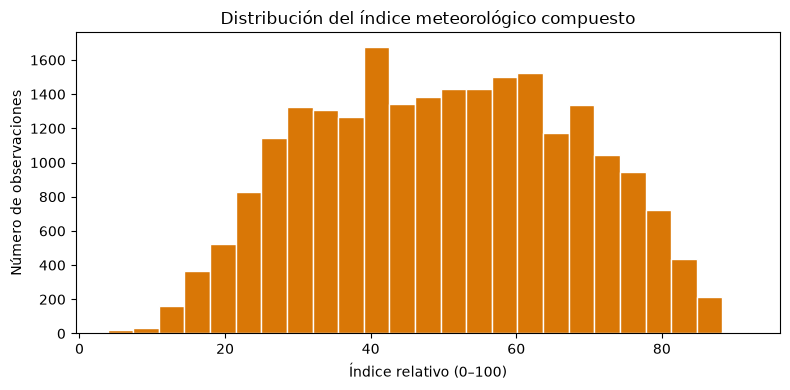

,observaciones,indice_medio,indice_mediano
ccaa,,,
Madrid,199,65.791018,75.493907
Castilla-La Mancha,1583,62.523769,64.190865
Andalucía,3299,61.065056,64.476385
Islas Baleares,115,60.237394,62.051141
Extremadura,3161,58.632141,56.585321
Región de Murcia,516,57.546244,59.638212
Comunidad Valenciana,1539,54.234014,57.145990
Canarias,2733,52.247814,54.370085
Aragón,714,52.192098,50.742967


CSV enriquecido guardado en: data/processed/expanded/firms_spain_final_lags_index.csv


In [7]:
display(df['indice_meteorologico'].describe(percentiles=[.1, .25, .5, .75, .9]).to_frame())
ax = df['indice_meteorologico'].dropna().plot(kind='hist', bins=25, figsize=(8, 4), color='#d97706', edgecolor='white')
ax.set(title='Distribución del índice meteorológico compuesto', xlabel='Índice relativo (0–100)', ylabel='Número de observaciones')
plt.tight_layout()
plt.show()

if 'ccaa' in df.columns:
    resumen_ccaa = (df.groupby('ccaa', dropna=False)
                    .agg(observaciones=('indice_meteorologico', 'count'),
                         indice_medio=('indice_meteorologico', 'mean'),
                         indice_mediano=('indice_meteorologico', 'median'))
                    .sort_values('indice_medio', ascending=False))
    display(resumen_ccaa)

output_path = 'data/processed/expanded/firms_spain_final_lags_index.csv'
save_csv(df, output_path)
print(f'CSV enriquecido guardado en: {output_path}')